# COMP3220 Assignment 4: Heart Disease Prediction

**Group members**: Alexia Barrows (620161540) and Daniel Graham (620171166)

**Description** <br>
You are given medical data on several patients. Your job is to use this data to build a model that
predicts whether a patient has heart disease. A Jupyter notebook is provided, along with two
CSV files: heart_train.csv and heart_test.csv. Edit the notebook to complete the objectives
below. This assignment is based on the Kaggle Heart Failure Prediction COMP3220 (UWI)
competition.

https://scikit-learn.org/stable/api/sklearn.html <br>
https://youtu.be/VXtjG_GzO7Q?si=TsvXcg_4FSpvGSfG


### Import Libraries
Run *pip install -r requirements.txt first*

In [62]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,classification_report,
                             ConfusionMatrixDisplay, f1_score, confusion_matrix)

RANDOM_STATE = 42

### 1. Read heart_train.csv into a pandas dataframe.

In [63]:
train = pd.read_csv("heart_train.csv")
test = pd.read_csv("heart_test.csv")

print("\nFirst 5 rows of training data:")
train.head()


First 5 rows of training data:


,PatientId,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0,34,M,ATA,150,214,0,ST,168,N,0.0,Up,0
1,1,59,M,ASY,178,0,1,LVH,120,Y,0.0,Flat,1
2,2,58,M,ASY,115,0,1,Normal,138,N,0.5,Up,1
3,3,60,M,ASY,130,253,0,Normal,144,Y,1.4,Up,1
4,4,52,M,ASY,165,0,1,Normal,122,Y,1.0,Up,1


### 2. Pre-process and clean your data so it is ready for training

Check for null values, duplicate rows, impossible values and class balance.

In [64]:
print("Null values in train:", int(train.isnull().sum().sum()))
print("Null values in test:", int(test.isnull().sum().sum()))
print("Duplicate rows in train:", int(train.duplicated().sum()))

train = train.drop_duplicates().reset_index(drop=True)

print("Cholesterol == 0 : train", int((train.Cholesterol == 0).sum()), "| test", int((test.Cholesterol == 0).sum()))
print("RestingBP == 0 : train", int((train.RestingBP == 0).sum()), "| test", int((test.RestingBP == 0).sum()))

medians = {}
for col in ['Cholesterol', 'RestingBP']:
    med = train.loc[train[col] != 0, col].median()
    medians[col] = med
    num_zero_train = (train[col] == 0).sum()
    num_zero_test = (test[col] == 0).sum()
    train.loc[train[col] == 0, col] = med
    test.loc[test[col] == 0, col] = med
    print(f"{col}: train zeros={num_zero_train}, test zeros={num_zero_test}: replaced with median {med:.1f}")

Null values in train: 0
Null values in test: 0
Duplicate rows in train: 0
Cholesterol == 0 : train 151 | test 21
RestingBP == 0 : train 1 | test 0
Cholesterol: train zeros=151, test zeros=21: replaced with median 235.0
RestingBP: train zeros=1, test zeros=0: replaced with median 130.0


### 3. Choose the features to use (for example RestingBP, Cholesterol, FastingBS)
### 4. Extract the HeartDisease column to use as the labels for your model.

In [65]:
numeric_features     = ['Age','RestingBP','Cholesterol','MaxHR','Oldpeak','FastingBS']
categorical_features = ['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope']
all_features         = numeric_features + categorical_features

# extract labels
X = train[all_features]
y = train['HeartDisease']

# preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False),
     categorical_features)
])

### 5. Split the dataset into train and test sets using the train_test_split function.

80% train and 20% test, stratified so both parts keep the same class ratio, with random_state=42 so results are repeatable.

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Train: {X_train.shape[0]}\tTest: {X_test.shape[0]}")
print("Train positive rate:", round(y_train.mean(), 3))
print("Test positive rate:", round(y_test.mean(), 3))

Train: 654	Test: 164
Train positive rate: 0.546
Test positive rate: 0.543


In [67]:
results = []

def evaluate(model, X_te, y_te, name):
    y_pred = model.predict(X_te)
    row = {
        'Model': name,
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall':    recall_score(y_te, y_pred, zero_division=0),
        'F1':        f1_score(y_te, y_pred, zero_division=0),
        'CM':        confusion_matrix(y_te, y_pred),
    }
    results.append(row)
    print(f"\n=== {name} ===")
    print(f"Accuracy: {row['Accuracy']*100:.2f}%")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"Recall: {row['Recall']:.4f}")
    print(f"F1: {row['F1']:.4f}")
    print("Confusion matrix:\n", row['CM'])
    print(classification_report(y_te, y_pred, target_names=['No Disease','Heart Disease']))
    return row

### 6. Create a Logistic Regression model and fit it to your training data.

In [68]:
logreg = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Age','RestingBP','Cholesterol',...,'RestingECG','ExerciseAngina', 'ST_Slope']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

### 7. Test the model on your test split and report the percentage accuracy.
### 8. Also report the precision, recall and F1 score, and the confusion matrix, for the model.


=== Logistic Regression ===
Accuracy: 87.20%
Precision: 0.8864
Recall: 0.8764
F1: 0.8814
Confusion matrix:
 [[65 10]
 [11 78]]
               precision    recall  f1-score   support

   No Disease       0.86      0.87      0.86        75
Heart Disease       0.89      0.88      0.88        89

     accuracy                           0.87       164
    macro avg       0.87      0.87      0.87       164
 weighted avg       0.87      0.87      0.87       164



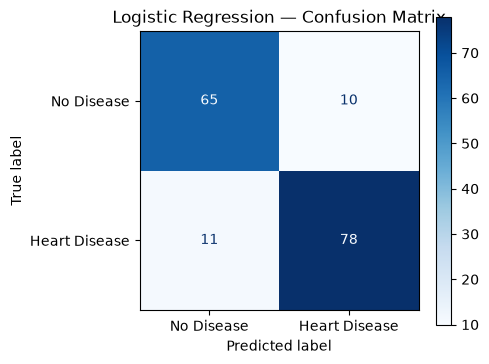

In [69]:
logreg_row = evaluate(logreg, X_test, y_test, "Logistic Regression")

# Confusion-matrix plot
fig, ax = plt.subplots(figsize=(4.5,4))
ConfusionMatrixDisplay(logreg_row['CM'],
    display_labels=['No Disease','Heart Disease']).plot(ax=ax, cmap='Blues')
ax.set_title("Logistic Regression — Confusion Matrix")
plt.show()

### 9. Create a simple neural network and fit it to your training data.
### 10. Test the neural network on your test split and report the percentage accuracy